# QFF final solution: the four-qubit ring classifier

Predict **alfalfa, maize or wheat** from satellite measurements. Follow the organizer's flow: load data, prepare four inputs, inspect the circuit, then evaluate real fields.

**Run All loads verified models; it does not retrain.** Training is optional at the end. Use Python 3.12 and the repository's `requirements.txt`.

Our ring has **12 trainable angles and two entanglement blocks**. Its fast trainer is **classical CPU simulation using Qiskit-generated operators and NumPy matrix-adjoint gradients**. This is not quantum hardware acceleration or a quantum-advantage claim.

In [1]:
from pathlib import Path
import json, sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = Path.cwd()
if not (ROOT / 'challenge').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'qff_solution').is_dir(), 'Open this notebook inside the cloned repository.'
sys.path.insert(0, str(ROOT))
assert sys.version_info[:2] == (3, 12), 'Select the project Python 3.12 kernel.'

from challenge.data import load_data
from challenge.models import angles
from challenge.metrics import score
from qff_solution import FinalRingClassifier
from qff_solution.demo import (ARTIFACTS, LABELS, NAMES, verify_artifacts,
                               evaluate_saved, recorded_runs, train_ring)

tables, supplied_view, manifest, _ = load_data(ROOT)
train, validation = tables['train'], tables['validation']
features = manifest['features']
raw_train, raw_val = train[features].to_numpy(), validation[features].to_numpy()
verify_artifacts()
prep = joblib.load(ARTIFACTS / 'preprocessing.joblib')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Data and saved-model checksums passed. Test labels remain private.')
display(pd.DataFrame({'split': tables.keys(), 'fields': [len(t) for t in tables.values()]}))

Matplotlib is building the font cache; this may take a moment.


Data and saved-model checksums passed. Test labels remain private.


,split,fields
0,train,914
1,validation,150
2,test,221


## 1. Prepare inputs and inspect the data

The 13 inputs are 12 satellite bands and NDVI. IDs and crop labels are never inputs. **PCA mixes these into four summaries**, like summarizing 13 measurements with four coordinates. We standardize before and after PCA; every fitted transformation comes from the 914 training fields only.

In the scatter plot, each dot is a real training field. Overlapping colors show why two coordinates alone cannot perfectly separate crops. The bars show how much feature variation each retained component captures; this is not a measure of classification accuracy.

,sample_id,B4,B8,NDVI,target
0,r2_628897512b6a2af8,1412.509516,3022.922050,0.362266,wheat
1,r2_52d40a7666662fbd,1598.965384,2880.773913,0.286029,wheat
2,r2_e76f16082a693985,1904.760633,3130.940754,0.244120,wheat
3,r2_3839538f981ce331,2361.372939,3499.690057,0.195382,wheat
4,r2_f7cf7a2cbbff3f42,1346.803236,2910.387379,0.371730,maize


,training,validation
target,,
alfalfa,247,50
maize,242,50
wheat,425,50


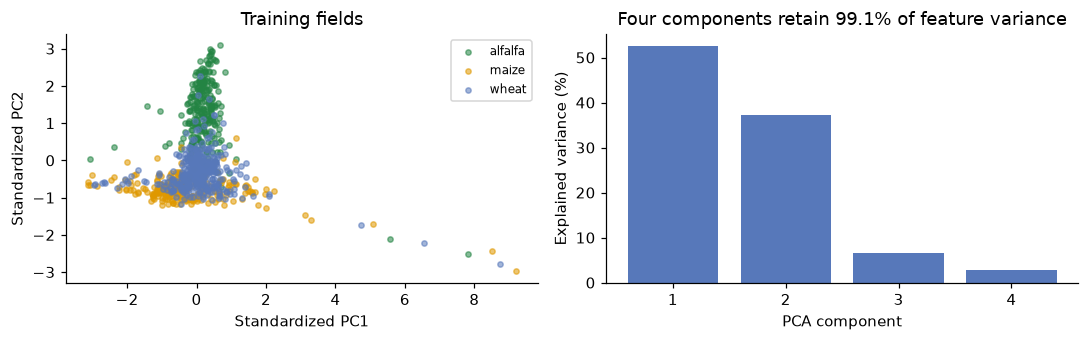

In [2]:
A, B = prep.transform(raw_train), prep.transform(raw_val)
np.testing.assert_allclose(A, supplied_view['X_train'], atol=1e-10, rtol=0)
display(train[['sample_id', 'B4', 'B8', 'NDVI', 'target']].head())
display(pd.DataFrame({'training': train.target.value_counts(),
                      'validation': validation.target.value_counts()}).loc[LABELS])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for crop, color in zip(LABELS, ['#238443', '#df9800', '#5778ba']):
    mask = train.target.to_numpy() == crop
    axes[0].scatter(A[mask, 0], A[mask, 1], s=12, alpha=.55, label=crop, color=color)
axes[0].set(xlabel='Standardized PC1', ylabel='Standardized PC2', title='Training fields')
axes[0].legend(fontsize=8)
variance = prep.named_steps['pca'].explained_variance_ratio_
axes[1].bar(range(1, 5), variance * 100, color='#5778ba')
axes[1].set(xticks=range(1, 5), xlabel='PCA component', ylabel='Explained variance (%)',
            title=f'Four components retain {variance.sum():.1%} of feature variance')
fig.tight_layout()
plt.show()

## 2. Understand the model

Each standardized PCA value `z` becomes an RY rotation angle **`(π/2) × (1 + tanh(z))`**. The circuit then applies three banks of four learned RY angles, with two ring blocks between them: **0 → 1 → 2 → 3 → 0**. CX gates connect the qubits so the model can use their joint behavior.

The final 16 outcomes are grouped by **integer outcome modulo 3** into alfalfa, maize and wheat. L-BFGS-B changes the 12 angles to reduce cross-entropy: confident wrong answers receive a larger penalty. The adjoint computes all derivatives in a backward pass, replacing 24 shifted probability evaluations per gradient. The circuit, loss and readout stay unchanged.

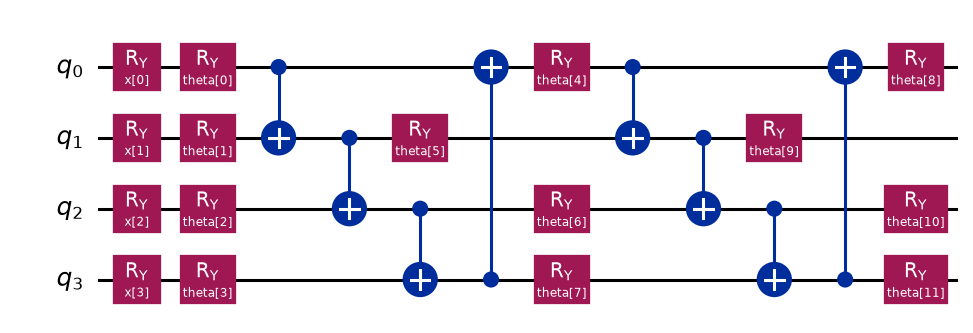

,qubits,PCA inputs,trainable angles,ring blocks,CX gates,logical depth,optimizer,max loss/gradient calls
0,4,4,12,2,8,12,L-BFGS-B,100


In [3]:
circuit_model = FinalRingClassifier()
display(circuit_model.circuit.draw('mpl', fold=-1))
display(pd.DataFrame([{'qubits': 4, 'PCA inputs': 4, 'trainable angles': 12,
                        'ring blocks': 2, 'CX gates': 8,
                        'logical depth': circuit_model.circuit.depth(),
                        'optimizer': 'L-BFGS-B', 'max loss/gradient calls': 100}]))

In [4]:
# Recompute validation predictions now from the bundled weights, for ALL seeds.
# Each result must match the saved field-by-field predictions.
replay = {seed: evaluate_saved(raw_val, validation.target.to_numpy(),
                              validation.sample_id.to_numpy(), seed) for seed in [0, 1, 2]}
demo = replay[0]  # Fixed demonstration seed; never chosen by validation score.
models = demo['models']
rows = [{'model': NAMES[key], 'seed': seed,
         'macro_F1': result['metrics'][key]['macro_f1'],
         'accuracy': result['metrics'][key]['accuracy']}
        for seed, result in replay.items() for key in NAMES]
scores = pd.DataFrame(rows)
print('Fresh inference matches every archived validation prediction for seeds 0, 1 and 2.')

Fresh inference matches every archived validation prediction for seeds 0, 1 and 2.


## 3. Interpret the validation results

**Accuracy** is the fraction of correct fields. **Precision** asks: of fields predicted as wheat, how many really are wheat? **Recall** asks: of all real wheat fields, how many did we find? Macro-F1 balances precision and recall for each crop, then gives the three crops equal weight.

These are **observed validation results, not an unseen-test score**. Earlier training-only topology CV selected full connectivity; ring was the strongest observed validation candidate. The fast gradient was selected separately using training-only CV: **0.8527 mean out-of-fold macro-F1**, with the same predictions as parameter-shift. We did not choose the best validation seed. The original SVM uses all 13 features; both QNNs use the same four PCA inputs.

In [5]:
summary = scores.groupby('model', sort=False).agg(
    macro_F1_mean=('macro_F1', 'mean'), macro_F1_seed_SD=('macro_F1', lambda s: s.std(ddof=0)),
    accuracy_mean=('accuracy', 'mean'))
display(summary.round(4))
display(scores.pivot(index='seed', columns='model', values='macro_F1').round(4))
crop_rows = [{'model': NAMES[key], 'crop': crop,
              'precision': demo['metrics'][key]['precision'][j],
              'recall': demo['metrics'][key]['recall'][j]}
             for key in NAMES for j, crop in enumerate(LABELS)]
print('Per-crop metrics below use the fixed seed-0 demonstration, not a seed average:')
display(pd.DataFrame(crop_rows).set_index(['model', 'crop']).round(4))
print('Final ring: 134/150 correct (89.33%), macro-F1 0.8943 for all three seeds.')
print('Versus SVM at seed 0: ring finds 4 more wheat fields, but 1 fewer maize and 1 fewer alfalfa.')
print('Wheat recall improves to 92%; wheat precision falls to 80.70% because 11 non-wheat fields are called wheat.')

,macro_F1_mean,macro_F1_seed_SD,accuracy_mean
model,,,
Final ring QNN,0.8943,0.000,0.8933
Original QNN,0.8557,0.006,0.8556
Classical SVM,0.8797,0.000,0.8800


model,Classical SVM,Final ring QNN,Original QNN
seed,,,
0,0.8797,0.8943,0.8473
1,0.8797,0.8943,0.8586
2,0.8797,0.8943,0.8612


Per-crop metrics below use the fixed seed-0 demonstration, not a seed average:


precision  recall
model          crop                      
Final ring QNN alfalfa     0.9200    0.92
               maize       0.9767    0.84
               wheat       0.8070    0.92
Original QNN   alfalfa     0.7818    0.86
               maize       0.8776    0.86
               wheat       0.8913    0.82
Classical SVM  alfalfa     0.8868    0.94
               maize       0.9149    0.86
               wheat       0.8400    0.84

Final ring: 134/150 correct (89.33%), macro-F1 0.8943 for all three seeds.
Versus SVM at seed 0: ring finds 4 more wheat fields, but 1 fewer maize and 1 fewer alfalfa.
Wheat recall improves to 92%; wheat precision falls to 80.70% because 11 non-wheat fields are called wheat.


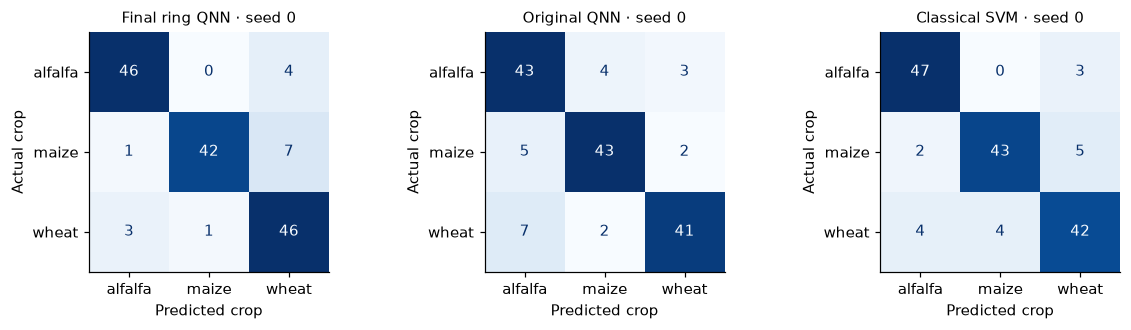

In [6]:
# Rows = actual crop; columns = predicted crop. Off-diagonal counts are errors.
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1))
for ax, key in zip(axes, NAMES):
    ConfusionMatrixDisplay(np.array(demo['metrics'][key]['confusion']),
                           display_labels=LABELS).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(NAMES[key] + ' · seed 0', fontsize=10)
    ax.set_xlabel('Predicted crop')
    ax.set_ylabel('Actual crop')
fig.tight_layout()
plt.show()

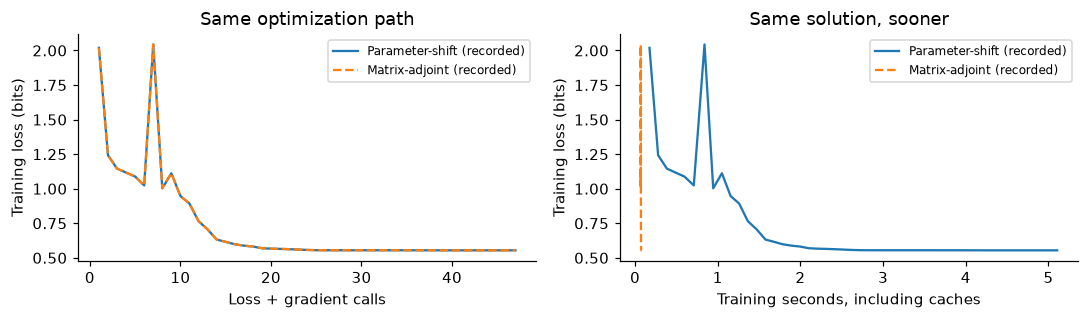

In [7]:
# Recorded same-circuit training curves: lower cross-entropy is better.
fast_history = pd.DataFrame(models['ring'].history)
shift_history = pd.read_json(ARTIFACTS / 'ring_parameter_shift_seed_0_history.json')
np.testing.assert_allclose(fast_history.objective_bits, shift_history.objective_bits, atol=1e-7, rtol=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for history, label, style in [(shift_history, 'Parameter-shift (recorded)', '-'),
                               (fast_history, 'Matrix-adjoint (recorded)', '--')]:
    axes[0].plot(history.evaluation, history.objective_bits, style, label=label)
    axes[1].plot(history.seconds, history.objective_bits, style, label=label)
axes[0].set(xlabel='Loss + gradient calls', ylabel='Training loss (bits)', title='Same optimization path')
axes[1].set(xlabel='Training seconds, including caches', ylabel='Training loss (bits)', title='Same solution, sooner')
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Read the timing comparison:** the table below reports recorded medians across seeds 0/1/2, including each fit's caches. The paired 12-angle benchmark used the same machine and standard Qiskit inference: approximately **5.705 → 0.177 seconds total**, preserving predictions. Training alone was **5.605 → 0.082 seconds**. These are measured CPU-simulation improvements, not hardware acceleration.

The original QNN's timing is an **equivalent cached COBYLA replay**, not the slower organizer training loop. Its and SVM's timings came from another session on the same machine and exclude model construction; the paired ring timings include it. Imports, saved-file loading and plotting are excluded. Your new inference times are shown separately; Run All does not measure fresh training unless you enable it below.

In [8]:
records = pd.DataFrame(recorded_runs())
timing_names = {**NAMES, 'ring_parameter_shift': 'Same ring · parameter-shift'}
timing = records.groupby('model', sort=False)[
    ['preprocessing_seconds', 'fit_seconds', 'inference_seconds', 'total_seconds']].median()
timing.index = [timing_names[k] for k in timing.index]
print('RECORDED local CPU times (seconds); total is the median of per-run totals:')
display(timing.round(6))
print('FRESH saved-model inference on this execution, seed 0 (150 validation fields):')
display(pd.DataFrame(demo['timings']).round(6))
print(f"Shared saved-model loading: {demo['load_seconds']:.4f}s; PCA transform: {demo['transform_seconds']:.4f}s")

RECORDED local CPU times (seconds); total is the median of per-run totals:


,preprocessing_seconds,fit_seconds,inference_seconds,total_seconds
Same ring · parameter-shift,0.001187,5.604531,0.098222,5.704809
Final ring QNN,0.001267,0.082123,0.092839,0.177378
Original QNN,0.001074,0.489688,0.081153,0.574118
Classical SVM,0.000291,0.004793,0.000888,0.006000


FRESH saved-model inference on this execution, seed 0 (150 validation fields):


,model,inference_seconds_now
0,Final ring QNN,0.091376
1,Original QNN,0.081014
2,Classical SVM,0.001046


Shared saved-model loading: 0.0032s; PCA transform: 0.0003s


## 4. Predict one real validation field

Change `FIELD_INDEX` to any integer from **0 to 149**. The label is revealed only after prediction; it never enters the model. The three quantum probabilities sum to one, but are not guaranteed to be calibrated confidence estimates. This field was part of validation, so it is a demonstration, not a new test.

In [9]:
FIELD_INDEX = 0
assert 0 <= FIELD_INDEX < len(validation)
field = validation.iloc[FIELD_INDEX]
prepared_field = demo['preprocessing'].transform(raw_val[FIELD_INDEX:FIELD_INDEX + 1])
probabilities = models['ring'].predict_proba(prepared_field)[0]
prediction = LABELS[int(probabilities.argmax())]
display(field[['sample_id', 'B4', 'B8', 'NDVI']].to_frame('measurement'))
display(pd.DataFrame({'PCA input': prepared_field[0], 'RY angle (radians)': angles(prepared_field)[0]},
                     index=['PC1', 'PC2', 'PC3', 'PC4']).round(4))
display(pd.DataFrame({'crop': LABELS, 'ring probability': probabilities}).round(4))
print(f"Field {field.sample_id}: predicted {prediction}; actual {field.target}; correct = {prediction == field.target}")
print('Original QNN:', models['original'].predict(prepared_field)[0],
      '| Classical SVM:', models['svm'].predict(raw_val[FIELD_INDEX:FIELD_INDEX + 1])[0])

,measurement
sample_id,r2_4769de2441c6188e
B4,1463.892882
B8,2526.913981
NDVI,0.266827


,PCA input,RY angle (radians)
PC1,-0.3396,1.0570
PC2,-0.5222,0.8178
PC3,-0.1677,1.3098
PC4,-0.7581,0.5655


,crop,ring probability
0,alfalfa,0.0171
1,maize,0.0936
2,wheat,0.8894


Field r2_4769de2441c6188e: predicted wheat; actual wheat; correct = True
Original QNN: wheat | Classical SVM: wheat


## 5. Optional: retrain the final model

Leave `RETRAIN = False` for the quick demo. Set it to `True` and run this cell to fit the same model on **all 914 training fields, seeds 0/1/2**. Every seed starts from its original random angles; L-BFGS-B has the unchanged 100-call limit and fixed tolerances. Validation is used only to evaluate after fitting, with no setting or seed selection.

This uses the fast matrix-adjoint trainer and fresh caches. It checks all validation predictions against the verified artifacts, reports new timings, and saves a separate timestamped run under ignored `outputs/`. The demo models and historical results above remain unchanged. Timing depends on the machine; allow a few seconds after imports.

In [10]:
RETRAIN = False
if RETRAIN:
    from datetime import datetime, timezone
    destination = ROOT / 'outputs' / ('final_ring_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
    destination.mkdir(parents=True, exist_ok=False)
    fresh_rows = []
    for seed in [0, 1, 2]:
        fresh_prep, fresh_model, p, times = train_ring(raw_train, train.target.to_numpy(), raw_val, seed)
        pred = fresh_model.labels[p.argmax(axis=1)]
        np.testing.assert_array_equal(pred, replay[seed]['predictions']['ring'])
        np.testing.assert_allclose(p, replay[seed]['models']['ring'].predict_proba(B), atol=1e-7, rtol=0)
        metrics = score(validation.target, pred, LABELS)
        fresh_rows.append({'seed': seed, 'macro_F1': metrics['macro_f1'], 'accuracy': metrics['accuracy'], **times})
        np.savez_compressed(destination / f'seed_{seed}_weights.npz', initial=fresh_model.initial_point, final=fresh_model.model.weights)
        joblib.dump(fresh_prep, destination / f'seed_{seed}_preprocessing.joblib')
        (destination / f'seed_{seed}_history.json').write_text(json.dumps(fresh_model.history, indent=2))
    pd.DataFrame(fresh_rows).to_csv(destination / 'fresh_results.csv', index=False)
    display(pd.DataFrame(fresh_rows).round(6))
    print('Fresh training reproduced all validation predictions. Saved separately in', destination.relative_to(ROOT))
else:
    print('Retraining skipped. Everything above used verified saved weights and fresh inference.')

Retraining skipped. Everything above used verified saved weights and fresh inference.


**What we can defend:** the 12-angle ring is our strongest observed validation candidate; the faster trainer preserves that model's predictions. Zero variation in validation F1 across these three seeds does not guarantee stability on other splits. The SVM remains a strong, much faster classical reference. We do not claim quantum advantage.

Code: [`qff_solution/`](../qff_solution/). Saved weights, preprocessing, predictions, timing records and checksums: [`artifacts/final_ring/`](../artifacts/final_ring/). Configuration, selection and reproduction details: [release notes](../docs/FINAL_SOLUTION.md).

The [organizers' notebook](Qiskit_QuantumAfrica_Crop_Challenge.ipynb), data and original source files are preserved unchanged. No hardware credentials or research folders are required. Test labels have not been used.